# 1 · Porosity–depth fit

**What.** Fit one exponential compaction curve to the published porosity–depth curves for mudstone, sandstone and average marine sediment (BasinSubs `PoFun.csv` inputs).

**Why.** Decompaction (notebook 3) needs, for each lithology, a surface porosity φ₀ and a decay length *c*. Taking them from a fit to several published curves, with an honest uncertainty, is what makes the error bars on subsidence meaningful.

**Equation (Athy 1930).**

$$\phi(z) = \phi_0\, e^{-z/c}\qquad\Longleftrightarrow\qquad \ln\phi = \ln\phi_0 - z/c$$

| symbol | meaning | unit |
|---|---|---|
| φ(z) | porosity at depth z below seafloor | fraction |
| φ₀ | porosity at the seafloor | fraction |
| c | decay length (depth at which φ falls to φ₀/e) | m |
| z | burial depth below seafloor | m |

Each published curve is sampled every 50 m over its stated depth range, then `ln φ` is regressed on *z* (ordinary least squares). The 95 % band is the **confidence band of the mean curve**: $\exp(\hat y \pm t_{0.975,n-2}\,\sqrt{x_g^\top \Sigma x_g})$ where Σ is the coefficient covariance.

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, ROOT)
IMG = os.path.join(ROOT, "image"); os.makedirs(IMG, exist_ok=True)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})
def save(fig, name):
    fig.savefig(os.path.join(IMG, name), bbox_inches="tight"); print("saved image/" + name)

In [2]:
from pybasinsubs import data_path
from pybasinsubs.legacy import porosity_fit_r
from pybasinsubs.porosity import sample_curves, fit_exponential
from pybasinsubs.plotting import porosity_fit_plot
pofun = pd.read_csv(data_path("coastal_range", "Backstripping", "PoFun.csv"))
pofun

,Litho,Porosity_0,Porosity_0_err,DecayC,DecayC_err,rho_g,rho_g_err
0,Mdt,0.425305,0.019245,1502.024,44.32066,2649.000000,43.429637
1,Sst,0.373416,0.011402,2860.291,91.89712,2666.666667,8.819171
2,AvgMS,0.663000,0.033150,1333.000,66.65000,2647.000000,52.940000


The table above is what the R scripts produced (φ₀, *c* and their standard errors). We refit each lithology from the raw curve tables and check that the **legacy port** gives the same numbers as R, and that the **generic fit** agrees.

In [3]:
files = {"Mudstone": "Porosity_mud.csv", "Sandstone": "Porosity_sand.csv", "AveMarSed": "Porosity_marinesed.csv"}
rows = []; fits = {}
for name, f in files.items():
    tab = pd.read_csv(data_path("coastal_range", "Backstripping", f)).dropna(subset=["InitialPorosity"])
    leg = porosity_fit_r(tab)
    z, phi = sample_curves(tab)
    gen = fit_exponential(z, phi)
    fits[name] = (tab, z, phi, gen, leg)
    rows.append(dict(lithology=name, n_curves=len(tab), phi0_legacy=leg["phi0"], c_legacy=leg["C"],
                     phi0_generic=gen["phi0"], phi0_se=gen["phi0_se"], c_generic=gen["C"], c_se=gen["C_se"], r2=gen["r2"]))
res = pd.DataFrame(rows); res.round(4)

,lithology,n_curves,phi0_legacy,c_legacy,phi0_generic,phi0_se,c_generic,c_se,r2
0,Mudstone,19,0.4253,1502.0238,0.4253,0.0192,1502.0238,44.3207,0.5145
1,Sandstone,23,0.3734,2860.2905,0.3734,0.0114,2860.2905,91.8971,0.4333
2,AveMarSed,1,0.6630,1333.0000,0.6630,0.0000,1333.0000,0.0000,1.0000


In [4]:
print(pofun.columns.tolist())
# legacy vs the R output table (PoFun.csv)
for _, r in res.iterrows():
    print(f"{r.lithology:10s}  phi0 legacy {r.phi0_legacy:.5f}   c legacy {r.c_legacy:.2f} m")

['Litho', 'Porosity_0', 'Porosity_0_err', 'DecayC', 'DecayC_err', 'rho_g', 'rho_g_err']
Mudstone    phi0 legacy 0.42531   c legacy 1502.02 m
Sandstone   phi0 legacy 0.37342   c legacy 2860.29 m
AveMarSed   phi0 legacy 0.66300   c legacy 1333.00 m


## Figures — one per lithology

saved image/nb1_porosity_mudstone.png


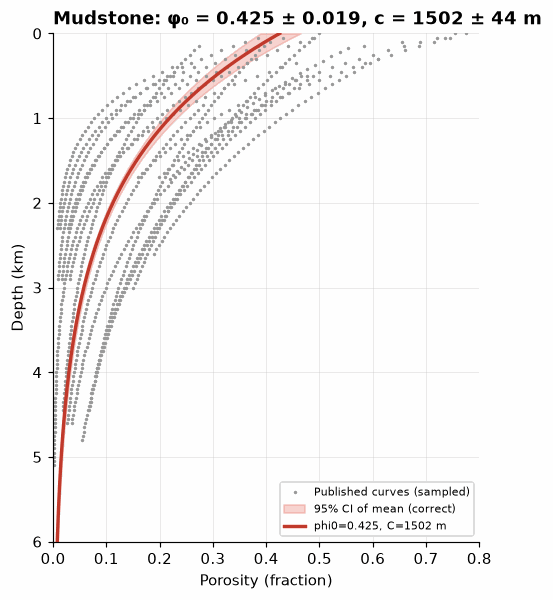

saved image/nb1_porosity_sandstone.png


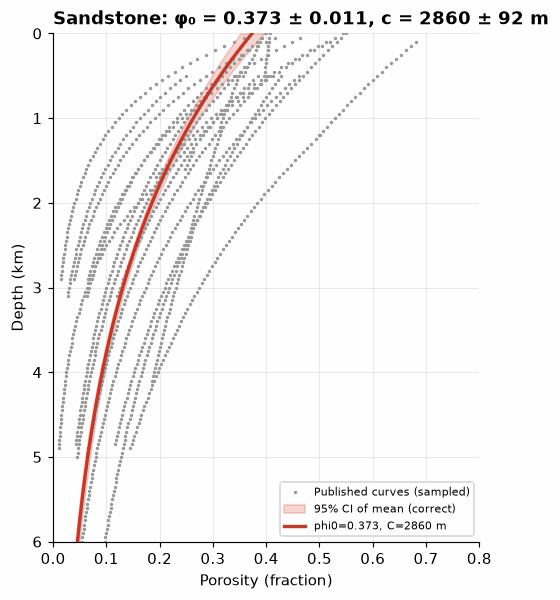

saved image/nb1_porosity_avemarsed.png


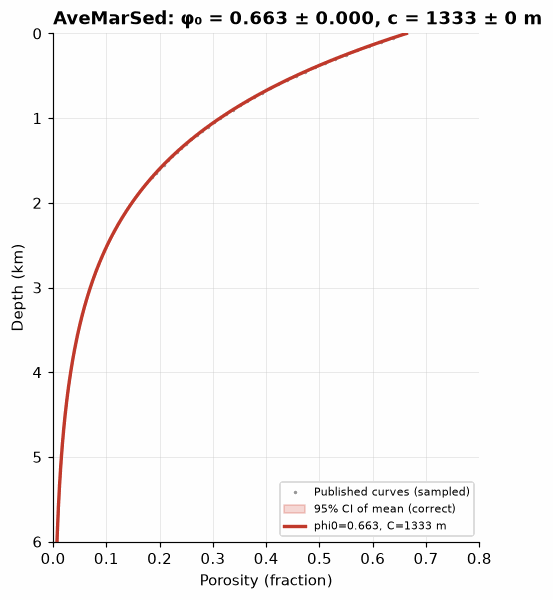

In [5]:
for name, (tab, z, phi, gen, leg) in fits.items():
    fig, ax = plt.subplots(figsize=(5, 6))
    porosity_fit_plot(z, phi, gen, ax=ax, title=f"{name}: φ₀ = {gen['phi0']:.3f} ± {gen['phi0_se']:.3f}, c = {gen['C']:.0f} ± {gen['C_se']:.0f} m")
    save(fig, f"nb1_porosity_{name.lower()}.png"); plt.show()

**How to read the panels.** Depth increases downward. Grey dots are the published curves sampled every 50 m; each different source is a separate streak of dots. The red line is the best-fit exponential and the shaded band is where the *average* curve lies with 95 % confidence. 

- **Mudstone** loses porosity fastest (smallest *c*): shale compacts quickly in the first 2 km.
- **Sandstone** keeps porosity deeper (larger *c*), so it decompacts less.
- **Average marine sediment** sits in between.

The spread of the dots around the line is much wider than the band: the band is the uncertainty of the *mean* curve, not the range of individual rocks. In the Monte Carlo backstrip we vary φ₀ and *c* using the standard errors listed in the table.